<a href="https://colab.research.google.com/github/aryaapkavi-stack/LithoAI/blob/main/notebooks/lithoai_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'secom_labels.data', 'secom.data', '.ipynb_checkpoints']


In [ ]:
import pandas as pd
import numpy as np

X = pd.read_csv("secom.data", sep=r"\s+", header=None)

labels = pd.read_csv(
    "secom_labels.data",
    sep=r"\s+",
    header=None
)

y = labels.iloc[:, 0]

print("Dataset shape:", X.shape)
print("Labels shape:", labels.shape)

print("\nPass/Fail distribution:")
print(y.value_counts())

print("\nTotal missing values:", X.isna().sum().sum())

print("\nMissing data percentage:",
      X.isna().sum().sum() / X.size * 100)

display(X.head())


Dataset shape: (1567, 590)
Labels shape: (1567, 2)

Pass/Fail distribution:
0
-1    1463
 1     104
Name: count, dtype: int64

Total missing values: 41951

Missing data percentage: 4.537548808583821


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [ ]:
# Examine missing values in individual sensor features

missing_per_feature = X.isna().sum()

print("Features with missing values:",
      (missing_per_feature > 0).sum())

print("\nFeatures with more than 50% missing data:",
      (missing_per_feature > len(X) * 0.5).sum())

print("\n10 features with the most missing values:")
print(missing_per_feature.sort_values(ascending=False).head(10))

print("\nLabel values:")
print(labels.head())

Features with missing values: 538

Features with more than 50% missing data: 28

10 features with the most missing values:
292    1429
293    1429
158    1429
157    1429
492    1341
85     1341
358    1341
220    1341
244    1018
517    1018
dtype: int64

Label values:
   0                    1
0 -1  19/07/2008 11:55:00
1 -1  19/07/2008 12:32:00
2  1  19/07/2008 13:17:00
3 -1  19/07/2008 14:43:00
4 -1  19/07/2008 15:22:00


In [ ]:
# Missing data analysis

missing_per_feature = X.isna().sum()

missing_percentage = (missing_per_feature / len(X)) * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_per_feature,
    "Missing_Percentage": missing_percentage
})

print("Features with 0% missing:",
      (missing_percentage == 0).sum())

print("Features with 1-25% missing:",
      ((missing_percentage > 0) & (missing_percentage <= 25)).sum())

print("Features with 25-50% missing:",
      ((missing_percentage > 25) & (missing_percentage <= 50)).sum())

print("Features with 50-75% missing:",
      ((missing_percentage > 50) & (missing_percentage <= 75)).sum())

print("Features with 75-100% missing:",
      (missing_percentage > 75).sum())

print("\nTimestamp range:")
timestamps = pd.to_datetime(
    labels.iloc[:, 1],
    dayfirst=True
)

print(timestamps.min())
print(timestamps.max())

Features with 0% missing: 52
Features with 1-25% missing: 506
Features with 25-50% missing: 4
Features with 50-75% missing: 20
Features with 75-100% missing: 8

Timestamp range:
2008-07-19 11:55:00
2008-10-17 06:07:00


In [ ]:
# Combine sensor data, labels and timestamps

df = X.copy()

df["label"] = y.values
df["timestamp"] = timestamps.values

# Check chronological ordering
print("Are observations chronologically sorted?",
      df["timestamp"].is_monotonic_increasing)

print("\nNumber of duplicate timestamps:",
      df["timestamp"].duplicated().sum())

# Group observations by month
df["month"] = df["timestamp"].dt.to_period("M")

monthly_results = df.groupby("month")["label"].agg(
    Total="count",
    Failures=lambda x: (x == 1).sum(),
    Passes=lambda x: (x == -1).sum()
)

print("\nMonthly pass/fail distribution:")
print(monthly_results)

# Missing data per observation
row_missing = X.isna().sum(axis=1)

print("\nAverage missing sensor readings per observation:",
      row_missing.mean())

print("Maximum missing sensor readings in one observation:",
      row_missing.max())

Are observations chronologically sorted? True

Number of duplicate timestamps: 33

Monthly pass/fail distribution:
         Total  Failures  Passes
month                           
2008-07     63        14      49
2008-08    555        51     504
2008-09    590        17     573
2008-10    359        22     337

Average missing sensor readings per observation: 26.771537970644545
Maximum missing sensor readings in one observation: 152


In [ ]:
# 1. Calculate monthly failure rates

monthly_results["Failure_Rate_%"] = (
    monthly_results["Failures"] /
    monthly_results["Total"] * 100
)

print("Monthly failure rates:")
print(monthly_results.round(2))


# 2. Investigate duplicate timestamps

duplicate_rows = df[
    df["timestamp"].duplicated(keep=False)
]

print("\nRows with duplicate timestamps:",
      len(duplicate_rows))

print("\nDo duplicate timestamps have conflicting labels?")

print(
    duplicate_rows.groupby("timestamp")["label"]
    .nunique()
    .value_counts()
)


# 3. Check class distribution in chronological sections

n = len(df)

first = df.iloc[:int(n * 0.70)]
middle = df.iloc[int(n * 0.70):int(n * 0.85)]
last = df.iloc[int(n * 0.85):]

for name, section in [
    ("First 70%", first),
    ("Next 15%", middle),
    ("Final 15%", last)
]:
    print("\n", name)
    print("Total:", len(section))
    print("Failures:", (section["label"] == 1).sum())
    print("Passes:", (section["label"] == -1).sum())

Monthly failure rates:
         Total  Failures  Passes  Failure_Rate_%
month                                           
2008-07     63        14      49           22.22
2008-08    555        51     504            9.19
2008-09    590        17     573            2.88
2008-10    359        22     337            6.13

Rows with duplicate timestamps: 65

Do duplicate timestamps have conflicting labels?
label
1    29
2     3
Name: count, dtype: int64

 First 70%
Total: 1096
Failures: 78
Passes: 1018

 Next 15%
Total: 235
Failures: 17
Passes: 218

 Final 15%
Total: 236
Failures: 9
Passes: 227


In [ ]:
# Find timestamps associated with conflicting labels

label_counts = (
    duplicate_rows.groupby("timestamp")["label"]
    .nunique()
)

conflicting_timestamps = label_counts[
    label_counts > 1
].index

print("Conflicting timestamps:")
print(conflicting_timestamps)

print("\nDetailed conflicting observations:")

for t in conflicting_timestamps:
    print("\nTimestamp:", t)

    display(
        df[df["timestamp"] == t][
            ["label", "timestamp"]
        ]
    )

Conflicting timestamps:
DatetimeIndex(['2008-08-05 07:12:00', '2008-08-31 10:59:00',
               '2008-10-05 00:33:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)

Detailed conflicting observations:

Timestamp: 2008-08-05 07:12:00


,label,timestamp
114,-1,2008-08-05 07:12:00
115,1,2008-08-05 07:12:00



Timestamp: 2008-08-31 10:59:00


,label,timestamp
605,1,2008-08-31 10:59:00
606,-1,2008-08-31 10:59:00



Timestamp: 2008-10-05 00:33:00


,label,timestamp
1303,1,2008-10-05 00:33:00
1304,-1,2008-10-05 00:33:00


In [ ]:
# Compare sensor readings for conflicting timestamps

for t in conflicting_timestamps:

    indices = df.index[df["timestamp"] == t].tolist()

    row1 = X.loc[indices[0]]
    row2 = X.loc[indices[1]]

    # Compare sensor readings, accounting for NaN values
    same_readings = np.array_equal(
        row1.to_numpy(),
        row2.to_numpy(),
        equal_nan=True
    )

    different_features = (
        (row1 != row2) &
        ~(row1.isna() & row2.isna())
    ).sum()

    print("\nTimestamp:", t)
    print("Observation indices:", indices)
    print("Identical sensor readings:", same_readings)
    print("Number of different sensor features:",
          different_features)


Timestamp: 2008-08-05 07:12:00
Observation indices: [114, 115]
Identical sensor readings: False
Number of different sensor features: 427

Timestamp: 2008-08-31 10:59:00
Observation indices: [605, 606]
Identical sensor readings: False
Number of different sensor features: 429

Timestamp: 2008-10-05 00:33:00
Observation indices: [1303, 1304]
Identical sensor readings: False
Number of different sensor features: 439


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Convert labels:
# -1 (Pass) -> 0
#  1 (Fail) -> 1

y_binary = (y == 1).astype(int)

# Group observations by timestamp
groups = timestamps

# Create 5 stratified group folds
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the first fold for our initial experiment
train_idx, test_idx = next(
    sgkf.split(X, y_binary, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y_binary.iloc[train_idx]
y_test = y_binary.iloc[test_idx]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTraining failure percentage:",
      y_train.mean() * 100)

print("Testing failure percentage:",
      y_test.mean() * 100)

Training observations: 1253
Testing observations: 314

Training class distribution:
0
0    1169
1      84
Name: count, dtype: int64

Testing class distribution:
0
0    294
1     20
Name: count, dtype: int64

Training failure percentage: 6.70391061452514
Testing failure percentage: 6.369426751592357


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score
)

# Step 1: Select features using training data only
keep_features = X_train.columns[
    X_train.isna().mean() <= 0.50
]

X_train_clean = X_train[keep_features]
X_test_clean = X_test[keep_features]

print("Original features:", X_train.shape[1])
print("Features retained:", len(keep_features))
print("Features removed:", X_train.shape[1] - len(keep_features))

# Step 2: Create our Logistic Regression pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Step 3: Train the model
model.fit(X_train_clean, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test_clean)
y_prob = model.predict_proba(X_test_clean)[:, 1]

# Step 5: Evaluate performance
print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred))

print("PR-AUC (Average Precision):",
      average_precision_score(y_test, y_prob))

Original features: 590
Features retained: 562
Features removed: 28

CONFUSION MATRIX:
[[265  29]
 [ 14   6]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        Pass       0.95      0.90      0.92       294
        Fail       0.17      0.30      0.22        20

    accuracy                           0.86       314
   macro avg       0.56      0.60      0.57       314
weighted avg       0.90      0.86      0.88       314

Balanced Accuracy: 0.6006802721088436
PR-AUC (Average Precision): 0.15045727953192714


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score
)

# Create Random Forest pipeline
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train_clean, y_train)

# Predict
rf_pred = rf_model.predict(X_test_clean)
rf_prob = rf_model.predict_proba(X_test_clean)[:, 1]

# Evaluate
print("RANDOM FOREST RESULTS")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, rf_pred))

print("PR-AUC:",
      average_precision_score(y_test, rf_prob))

RANDOM FOREST RESULTS

Confusion Matrix:
[[294   0]
 [ 20   0]]

Classification Report:
              precision    recall  f1-score   support

        Pass       0.94      1.00      0.97       294
        Fail       0.00      0.00      0.00        20

    accuracy                           0.94       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.88      0.94      0.91       314

Balanced Accuracy: 0.5
PR-AUC: 0.21167945155075057


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import numpy as np

# Create a validation split from training data
groups_train = groups.loc[X_train.index]

sgkf_val = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=21
)

sub_train_idx, val_idx = next(
    sgkf_val.split(X_train, y_train, groups_train)
)

X_subtrain = X_train.iloc[sub_train_idx]
X_val = X_train.iloc[val_idx]

y_subtrain = y_train.iloc[sub_train_idx]
y_val = y_train.iloc[val_idx]

# Use the same feature set selected earlier
X_subtrain = X_subtrain[keep_features]
X_val = X_val[keep_features]

# Train a fresh Random Forest on subtraining data
rf_validation = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_validation.fit(X_subtrain, y_subtrain)

# Get validation probabilities
val_prob = rf_validation.predict_proba(X_val)[:, 1]

# Evaluate different probability thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, val_prob
)

print("Validation observations:", len(X_val))
print("Validation failures:", y_val.sum())

print("\nPR-AUC:",
      average_precision_score(y_val, val_prob))

print("\nThreshold analysis:")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25,
                  0.30, 0.35, 0.40, 0.45, 0.50]:

    predictions = (val_prob >= threshold).astype(int)

    tp = ((predictions == 1) & (y_val.to_numpy() == 1)).sum()
    fp = ((predictions == 1) & (y_val.to_numpy() == 0)).sum()
    fn = ((predictions == 0) & (y_val.to_numpy() == 1)).sum()

    rec = tp / (tp + fn) if tp + fn else 0
    prec = tp / (tp + fp) if tp + fp else 0

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {prec:.3f} | "
        f"Recall: {rec:.3f} | "
        f"Detected failures: {tp}"
    )

Validation observations: 251
Validation failures: 24

PR-AUC: 0.3118244151776217

Threshold analysis:
Threshold: 0.05 | Precision: 0.126 | Recall: 0.917 | Detected failures: 22
Threshold: 0.10 | Precision: 0.262 | Recall: 0.458 | Detected failures: 11
Threshold: 0.15 | Precision: 0.500 | Recall: 0.167 | Detected failures: 4
Threshold: 0.20 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.25 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.30 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.35 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.40 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.45 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.50 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0


In [ ]:
# Inspect predicted failure probabilities

print("Minimum probability:", val_prob.min())
print("Maximum probability:", val_prob.max())

print("\nProbability distribution:")
print(pd.Series(val_prob).describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nNumber of observations flagged:")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.50]:
    flagged = (val_prob >= threshold).sum()

    print(
        f"Threshold {threshold:.2f}: "
        f"{flagged} observations"
    )

Minimum probability: 0.009703237410071942
Maximum probability: 0.19283433957761423

Probability distribution:
count    251.000000
mean       0.069611
std        0.033702
min        0.009703
25%        0.045266
50%        0.064325
75%        0.085960
90%        0.120161
95%        0.132607
99%        0.166661
max        0.192834
dtype: float64

Number of observations flagged:
Threshold 0.05: 175 observations
Threshold 0.10: 42 observations
Threshold 0.15: 8 observations
Threshold 0.20: 0 observations
Threshold 0.50: 0 observations


In [ ]:
# Corrected Random Forest validation experiment

# Select features using subtraining data ONLY
valid_features = X_subtrain.columns[
    X_subtrain.isna().mean() <= 0.50
]

X_subtrain_corrected = X_subtrain[valid_features]
X_val_corrected = X_val[valid_features]

print("Features selected:", len(valid_features))

# Build model
rf_corrected = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_corrected.fit(
    X_subtrain_corrected,
    y_subtrain
)

# Predict probabilities
corrected_prob = rf_corrected.predict_proba(
    X_val_corrected
)[:, 1]

# Evaluate
print("\nCorrected validation PR-AUC:",
      average_precision_score(y_val, corrected_prob))

print("\nCorrected probability distribution:")
print(pd.Series(corrected_prob).describe())

print("\nThreshold analysis:")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.50]:

    pred = (corrected_prob >= threshold).astype(int)

    tp = ((pred == 1) & (y_val.to_numpy() == 1)).sum()
    fp = ((pred == 1) & (y_val.to_numpy() == 0)).sum()
    fn = ((pred == 0) & (y_val.to_numpy() == 1)).sum()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"Detected: {tp}"
    )

Features selected: 562

Corrected validation PR-AUC: 0.3118244151776217

Corrected probability distribution:
count    251.000000
mean       0.069611
std        0.033702
min        0.009703
25%        0.045266
50%        0.064325
75%        0.085960
max        0.192834
dtype: float64

Threshold analysis:
Threshold: 0.05 | Precision: 0.126 | Recall: 0.917 | Detected: 22
Threshold: 0.10 | Precision: 0.262 | Recall: 0.458 | Detected: 11
Threshold: 0.15 | Precision: 0.500 | Recall: 0.167 | Detected: 4
Threshold: 0.20 | Precision: 0.000 | Recall: 0.000 | Detected: 0
Threshold: 0.25 | Precision: 0.000 | Recall: 0.000 | Detected: 0
Threshold: 0.50 | Precision: 0.000 | Recall: 0.000 | Detected: 0


In [ ]:
print(
    "Are both feature selections identical?",
    set(keep_features) == set(valid_features)
)

print(
    "Number of common features:",
    len(set(keep_features) & set(valid_features))
)

Are both feature selections identical? True
Number of common features: 562


In [ ]:
# MISSING SENSOR DATA ROBUSTNESS EXPERIMENT

from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

# Use the corrected validation features
X_robust = X_val_corrected.copy()

missing_levels = [0, 5, 10, 20, 30]

results = []

for level in missing_levels:

    # Create a reproducible copy
    X_test_missing = X_robust.copy()

    # Randomly hide additional sensor readings
    rng = np.random.default_rng(42)

    if level > 0:
        mask = rng.random(X_test_missing.shape) < (level / 100)

        X_test_missing = X_test_missing.mask(mask)

    # Predict using the same trained model
    probabilities = rf_corrected.predict_proba(
        X_test_missing
    )[:, 1]

    # Evaluate
    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    predictions = (probabilities >= 0.05).astype(int)

    tp = ((predictions == 1) &
          (y_val.to_numpy() == 1)).sum()

    fn = ((predictions == 0) &
          (y_val.to_numpy() == 1)).sum()

    recall = tp / (tp + fn) if tp + fn else 0

    results.append({
        "Additional Missing Data (%)": level,
        "PR-AUC": round(pr_auc, 4),
        "Failure Recall": round(recall, 4),
        "Detected Failures": int(tp)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Additional Missing Data (%)  PR-AUC  Failure Recall  Detected Failures
                           0  0.3118          0.9167                 22
                           5  0.2930          0.9583                 23
                          10  0.2764          0.9583                 23
                          20  0.2360          0.9583                 23
                          30  0.2120          1.0000                 24


In [ ]:
from sklearn.metrics import confusion_matrix

print("MISSING DATA FALSE-ALARM ANALYSIS")

for level in [0, 5, 10, 20, 30]:

    X_test_missing = X_robust.copy()

    rng = np.random.default_rng(42)

    if level > 0:
        mask = rng.random(X_test_missing.shape) < (level / 100)
        X_test_missing = X_test_missing.mask(mask)

    probabilities = rf_corrected.predict_proba(
        X_test_missing
    )[:, 1]

    predictions = (probabilities >= 0.05).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print(f"\nMissing data: {level}%")
    print("True positives:", tp)
    print("False positives:", fp)
    print("True negatives:", tn)
    print("False negatives:", fn)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))

MISSING DATA FALSE-ALARM ANALYSIS

Missing data: 0%
True positives: 22
False positives: 153
True negatives: 74
False negatives: 2
Precision: 0.1257
Recall: 0.9167

Missing data: 5%
True positives: 23
False positives: 162
True negatives: 65
False negatives: 1
Precision: 0.1243
Recall: 0.9583

Missing data: 10%
True positives: 23
False positives: 166
True negatives: 61
False negatives: 1
Precision: 0.1217
Recall: 0.9583

Missing data: 20%
True positives: 23
False positives: 176
True negatives: 51
False negatives: 1
Precision: 0.1156
Recall: 0.9583

Missing data: 30%
True positives: 24
False positives: 194
True negatives: 33
False negatives: 0
Precision: 0.1101
Recall: 1.0


In [ ]:
print("INSPECTION BURDEN ANALYSIS")

total = len(y_val)

for level, tp, fp, tn, fn in [
    (0, 22, 153, 74, 2),
    (5, 23, 162, 65, 1),
    (10, 23, 166, 61, 1),
    (20, 23, 176, 51, 1),
    (30, 24, 194, 33, 0)
]:
    flagged = tp + fp
    inspection_rate = (flagged / total) * 100
    unnecessary_rate = (fp / flagged) * 100

    print(f"\nMissingness: {level}%")
    print(f"Observations flagged: {flagged}/{total}")
    print(f"Inspection rate: {inspection_rate:.2f}%")
    print(f"Unnecessary inspections: {unnecessary_rate:.2f}%")

INSPECTION BURDEN ANALYSIS

Missingness: 0%
Observations flagged: 175/251
Inspection rate: 69.72%
Unnecessary inspections: 87.43%

Missingness: 5%
Observations flagged: 185/251
Inspection rate: 73.71%
Unnecessary inspections: 87.57%

Missingness: 10%
Observations flagged: 189/251
Inspection rate: 75.30%
Unnecessary inspections: 87.83%

Missingness: 20%
Observations flagged: 199/251
Inspection rate: 79.28%
Unnecessary inspections: 88.44%

Missingness: 30%
Observations flagged: 218/251
Inspection rate: 86.85%
Unnecessary inspections: 88.99%


In [ ]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score
)

levels = [0, 5, 10, 20, 30]
seeds = range(10)

repeated_results = []

for level in levels:
    for seed in seeds:

        X_missing = X_robust.copy()

        if level > 0:
            rng = np.random.default_rng(seed)
            mask = rng.random(X_missing.shape) < (level / 100)
            X_missing = X_missing.mask(mask)

        probabilities = rf_corrected.predict_proba(X_missing)[:, 1]
        predictions = (probabilities >= 0.05).astype(int)

        tp = ((y_val == 1) & (predictions == 1)).sum()
        fp = ((y_val == 0) & (predictions == 1)).sum()

        repeated_results.append({
            "Missingness": level,
            "Seed": seed,
            "PR_AUC": average_precision_score(y_val, probabilities),
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "Inspection_Rate": (tp + fp) / len(y_val)
        })

repeated_df = pd.DataFrame(repeated_results)

summary = repeated_df.groupby("Missingness").agg(
    PR_AUC_Mean=("PR_AUC", "mean"),
    PR_AUC_Std=("PR_AUC", "std"),
    Precision_Mean=("Precision", "mean"),
    Recall_Mean=("Recall", "mean"),
    Inspection_Rate_Mean=("Inspection_Rate", "mean")
)

print(summary.round(4))

             PR_AUC_Mean  PR_AUC_Std  Precision_Mean  Recall_Mean  \
Missingness                                                         
0                 0.3118      0.0000          0.1257       0.9167   
5                 0.3030      0.0317          0.1246       0.9292   
10                0.2956      0.0306          0.1232       0.9458   
20                0.2701      0.0438          0.1153       0.9667   
30                0.2642      0.0315          0.1069       0.9750   

             Inspection_Rate_Mean  
Missingness                        
0                          0.6972  
5                          0.7131  
10                         0.7343  
20                         0.8020  
30                         0.8721  


In [ ]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.6.1


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

# 1. Logistic Regression
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

lr_model.fit(X_subtrain_corrected, y_subtrain)

# 2. Existing Random Forest
# rf_corrected has already been trained on the same subtraining data.

# 3. HistGradientBoosting
hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    class_weight="balanced",
    random_state=42
)

hgb_model.fit(X_subtrain_corrected, y_subtrain)

# Evaluate all three on the same validation observations
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_corrected,
    "HistGradientBoosting": hgb_model
}

comparison = []

for name, model in models.items():
    probabilities = model.predict_proba(X_val_corrected)[:, 1]

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    comparison.append({
        "Model": name,
        "PR_AUC": pr_auc
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.sort_values(
    by="PR_AUC",
    ascending=False
).round(4))

                  Model  PR_AUC
1         Random Forest  0.3118
2  HistGradientBoosting  0.2131
0   Logistic Regression  0.1610


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.01, 0.51, 0.01):

    predictions = (val_prob >= threshold).astype(int)

    tp = ((y_val == 1) & (predictions == 1)).sum()
    fp = ((y_val == 0) & (predictions == 1)).sum()
    fn = ((y_val == 1) & (predictions == 0)).sum()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "Inspection_Rate": (tp + fp) / len(y_val),
        "False_Alarms": fp
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df[
    threshold_df["Recall"] >= 0.80
].round(4).to_string(index=False))

 Threshold  Precision  Recall     F1  Inspection_Rate  False_Alarms
      0.01     0.0960  1.0000 0.1752           0.9960           226
      0.02     0.0972  1.0000 0.1771           0.9841           223
      0.03     0.1043  1.0000 0.1890           0.9163           206
      0.04     0.1144  0.9583 0.2044           0.8008           178
      0.05     0.1257  0.9167 0.2211           0.6972           153
      0.06     0.1511  0.8750 0.2577           0.5538           118
      0.07     0.1869  0.8333 0.3053           0.4263            87


Preliminary observation: Increasing the classification threshold from 0.05 to 0.07 reduced the validation inspection rate from 69.72% to 42.63%, while recall decreased from 91.67% to 83.33%. Precision improved from 12.57% to 18.69%.

This suggests that threshold selection can substantially influence the balance between failure detection and inspection workload.

Important: 0.07 is a promising candidate, not our final chosen threshold. We selected it after looking at validation results, so we must use a separate final test set for an unbiased performance estimate.

In [ ]:
from sklearn.metrics import confusion_matrix

thresholds = [0.05, 0.06, 0.07]
missing_levels = [0, 5, 10, 20, 30]

threshold_robustness = []

for level in missing_levels:

    X_missing = X_robust.copy()

    if level > 0:
        rng = np.random.default_rng(42)
        mask = rng.random(X_missing.shape) < (level / 100)
        X_missing = X_missing.mask(mask)

    probabilities = rf_corrected.predict_proba(X_missing)[:, 1]

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        threshold_robustness.append({
            "Missingness": level,
            "Threshold": threshold,
            "Precision": tp / (tp + fp) if tp + fp else 0,
            "Recall": tp / (tp + fn) if tp + fn else 0,
            "Inspection_Rate": (tp + fp) / len(y_val),
            "False_Alarms": fp
        })

robustness_df = pd.DataFrame(threshold_robustness)

print(robustness_df.round(4).to_string(index=False))

 Missingness  Threshold  Precision  Recall  Inspection_Rate  False_Alarms
           0       0.05     0.1257  0.9167           0.6972           153
           0       0.06     0.1511  0.8750           0.5538           118
           0       0.07     0.1869  0.8333           0.4263            87
           5       0.05     0.1243  0.9583           0.7371           162
           5       0.06     0.1438  0.8750           0.5817           125
           5       0.07     0.1802  0.8333           0.4422            91
          10       0.05     0.1217  0.9583           0.7530           166
          10       0.06     0.1355  0.8750           0.6175           134
          10       0.07     0.1736  0.8750           0.4821           100
          20       0.05     0.1156  0.9583           0.7928           176
          20       0.06     0.1250  0.9167           0.7012           154
          20       0.07     0.1458  0.8750           0.5737           123
          30       0.05     0.1101  1.

Across the evaluated missing-data conditions, increasing the classification threshold from 0.05 to 0.07 reduced the inspection rate. However, inspection burden continued to increase with additional missingness, even at the higher threshold. This indicates that threshold adjustment alone may not be sufficient to maintain inspection efficiency under degraded sensor availability.

In [ ]:
print("Total observations:", len(X))
print("Unique timestamp groups:", groups.nunique())
print("Total features:", X.shape[1])
print("Failure observations:", (y == 1).sum())
print("Passing observations:", (y == -1).sum())

Total observations: 1567
Unique timestamp groups: 1534
Total features: 590
Failure observations: 104
Passing observations: 1463


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

# Convert labels: pass = 0, fail = 1
y_binary = (y == 1).astype(int)

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("variance", VarianceThreshold()),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y_binary, groups=groups), start=1
):

    X_tr = X.iloc[train_idx]
    X_va = X.iloc[val_idx]

    y_tr = y_binary.iloc[train_idx]
    y_va = y_binary.iloc[val_idx]

    for name, model in models.items():

        fitted_model = clone(model)
        fitted_model.fit(X_tr, y_tr)

        probabilities = fitted_model.predict_proba(X_va)[:, 1]

        score = average_precision_score(y_va, probabilities)

        cv_results.append({
            "Fold": fold,
            "Model": name,
            "PR_AUC": score,
            "Validation_Failures": int(y_va.sum()),
            "Validation_Size": len(y_va)
        })

results = pd.DataFrame(cv_results)

print("INDIVIDUAL FOLD RESULTS")
print(results.round(4).to_string(index=False))

print("\nCROSS-VALIDATION SUMMARY")
print(
    results.groupby("Model")["PR_AUC"]
    .agg(["mean", "std"])
    .round(4)
)

INDIVIDUAL FOLD RESULTS
 Fold                Model  PR_AUC  Validation_Failures  Validation_Size
    1  Logistic Regression  0.1567                   20              314
    1        Random Forest  0.2534                   20              314
    1 HistGradientBoosting  0.2539                   20              314
    2  Logistic Regression  0.1567                   18              314
    2        Random Forest  0.3221                   18              314
    2 HistGradientBoosting  0.2906                   18              314
    3  Logistic Regression  0.1536                   24              315
    3        Random Forest  0.1306                   24              315
    3 HistGradientBoosting  0.1538                   24              315
    4  Logistic Regression  0.1176                   16              309
    4        Random Forest  0.1201                   16              309
    4 HistGradientBoosting  0.1015                   16              309
    5  Logistic Regression 

### Dataset Characteristics and Experimental Considerations

The SECOM dataset consists of 1,567 semiconductor manufacturing observations and 590 sensor-related features. It contains 1,463 passing observations and 104 failing observations, indicating a substantial class imbalance. Additionally, the dataset contains missing sensor readings across multiple features, making incomplete data an important consideration in predictive modelling.

An examination of the timestamps identified 1,534 unique timestamp groups, meaning that some observations share identical timestamps. To avoid potential information leakage, observations belonging to the same timestamp group are kept together during grouped cross-validation. This ensures that records sharing a timestamp are not distributed across separate training and validation folds.

The class imbalance and missing sensor values present two important challenges: reliable identification of failure cases and maintaining predictive performance when sensor information is incomplete. These challenges form the basis of the experimental evaluation conducted in this study.

### Grouped Cross-Validation and Comparative Model Evaluation

To evaluate model performance across different subsets of the SECOM dataset, five-fold Stratified Group Cross-Validation was performed using timestamp groups. This approach ensured that observations sharing the same timestamp were kept within the same fold, reducing the possibility of information leakage between training and validation data.

Three classification algorithms were evaluated: Logistic Regression, Random Forest and HistGradientBoosting. All models were assessed using the area under the Precision-Recall curve (PR-AUC), which is particularly relevant for the imbalanced class distribution in the dataset.

The mean PR-AUC scores were 0.1568 for Logistic Regression, 0.2279 for Random Forest and 0.2289 for HistGradientBoosting. Although the two tree-based models achieved nearly identical average performance, their standard deviations were relatively high, indicating considerable variation across validation folds.

These results suggest that model performance is sensitive to the composition of the training and validation subsets. Consequently, neither Random Forest nor HistGradientBoosting can yet be established as a consistently superior model. Further evaluation is required before selecting the final modelling approach.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions = {
    name: np.full(len(X), np.nan)
    for name in models
}

fold_baselines = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y_binary, groups=groups), start=1
):

    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y_binary.iloc[train_idx], y_binary.iloc[val_idx]

    fold_baselines.append({
        "Fold": fold,
        "Failure_Prevalence": y_va.mean()
    })

    for name, model in models.items():

        fitted = clone(model)
        fitted.fit(X_tr, y_tr)

        oof_predictions[name][val_idx] = (
            fitted.predict_proba(X_va)[:, 1]
        )

print("FOLD FAILURE PREVALENCE")
print(pd.DataFrame(fold_baselines).round(4).to_string(index=False))

print("\nPOOLED OUT-OF-FOLD PR-AUC")

for name, probabilities in oof_predictions.items():

    score = average_precision_score(
        y_binary,
        probabilities
    )

    print(f"{name}: {score:.4f}")

print(
    "\nOverall failure prevalence:",
    round(y_binary.mean(), 4)
)

FOLD FAILURE PREVALENCE
 Fold  Failure_Prevalence
    1              0.0637
    2              0.0573
    3              0.0762
    4              0.0518
    5              0.0825

POOLED OUT-OF-FOLD PR-AUC
Logistic Regression: 0.1390
Random Forest: 0.1860
HistGradientBoosting: 0.1916

Overall failure prevalence: 0.0664


### Pooled Out-of-Fold Evaluation

To obtain a more comprehensive comparison, pooled out-of-fold predictions were generated using five-fold stratified group cross-validation, with observations sharing the same timestamp kept within the same fold. HistGradientBoosting achieved the highest pooled Precision-Recall AUC (0.1916), followed closely by Random Forest (0.1860), while Logistic Regression achieved 0.1390. The overall failure prevalence was 6.64%, providing a baseline for interpreting these results.

Although the two tree-based models performed better than Logistic Regression, their pooled scores were relatively close. Their performance also varied considerably across individual folds. Therefore, neither model can yet be considered a definitive winner. Both will be retained for further robustness and decision-threshold experiments.

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

thresholds = [0.05, 0.07, 0.10, 0.15, 0.20]

results = []

for model_name in ["Random Forest", "HistGradientBoosting"]:

    probabilities = oof_predictions[model_name]

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_binary, predictions
        ).ravel()

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_binary, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_binary, predictions, zero_division=0
            ),
            "Detected_Failures": tp,
            "False_Alarms": fp,
            "Inspection_Rate": predictions.mean()
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

               Model  Threshold  Precision  Recall  Detected_Failures  False_Alarms  Inspection_Rate
       Random Forest       0.05     0.0910  0.9231                 96           959           0.6733
       Random Forest       0.07     0.1116  0.7212                 75           597           0.4288
       Random Forest       0.10     0.1720  0.5673                 59           284           0.2189
       Random Forest       0.15     0.2059  0.2019                 21            81           0.0651
       Random Forest       0.20     0.3077  0.0769                  8            18           0.0166
HistGradientBoosting       0.05     0.1917  0.4423                 46           194           0.1532
HistGradientBoosting       0.07     0.2186  0.3846                 40           143           0.1168
HistGradientBoosting       0.10     0.2612  0.3365                 35            99           0.0855
HistGradientBoosting       0.15     0.2841  0.2404                 25            63        

### Comparative Analysis of Model Detection and Inspection Performance

The threshold-based evaluation revealed distinct operational behaviours between Random Forest and HistGradientBoosting. Random Forest achieved higher failure recall at lower thresholds, detecting 96 of 104 failure observations at a threshold of 0.05. However, this required flagging 67.33% of all observations for inspection.

In comparison, HistGradientBoosting detected 46 failure observations at the same threshold, while flagging only 15.32% of observations. At thresholds of 0.15 and 0.20, HistGradientBoosting also achieved higher failure recall than Random Forest while maintaining a lower inspection rate.

These results highlight the trade-off between failure detection and inspection workload. Random Forest is more aggressive in identifying potential failures, whereas HistGradientBoosting produces a more selective set of predictions. The findings suggest that model suitability should be assessed using both failure-detection performance and inspection burden rather than accuracy or PR-AUC alone. Further independent validation and threshold selection are required before drawing operational conclusions.

In [ ]:
from sklearn.metrics import recall_score
import numpy as np
import pandas as pd

target_recall = 0.80
operating_results = []

for model_name in ["Random Forest", "HistGradientBoosting"]:

    probabilities = oof_predictions[model_name]

    best_result = None

    for threshold in np.linspace(0, 1, 1001):

        predictions = (probabilities >= threshold).astype(int)

        recall = recall_score(
            y_binary,
            predictions,
            zero_division=0
        )

        if recall >= target_recall:

            inspection_rate = predictions.mean()

            if (
                best_result is None
                or inspection_rate < best_result["Inspection_Rate"]
            ):
                best_result = {
                    "Model": model_name,
                    "Threshold": threshold,
                    "Recall": recall,
                    "Inspection_Rate": inspection_rate,
                    "Detected_Failures": predictions[y_binary == 1].sum()
                }

    operating_results.append(best_result)

print(pd.DataFrame(operating_results).round(4).to_string(index=False))

               Model  Threshold  Recall  Inspection_Rate  Detected_Failures
       Random Forest      0.062  0.8173           0.5061                 85
HistGradientBoosting      0.007  0.8173           0.5680                 85


### Exploratory Operating-Point Selection at 80% Recall

An illustrative minimum recall target of 80% was used to compare the inspection requirements of the two models. Random Forest achieved a recall of 81.73% at a threshold of 0.062, flagging 50.61% of all observations. HistGradientBoosting achieved the same recall at a threshold of 0.007, but flagged 56.80% of observations.

Both models detected 85 out of 104 failure observations. Random Forest therefore required a smaller inspection set to achieve the same observed recall in this experiment. However, these operating points were selected and evaluated using the same pooled out-of-fold predictions. Consequently, the results are exploratory and may be optimistic. Independent threshold validation is required before interpreting them as estimates of generalisation performance.

In [ ]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    precision_score,
    recall_score,
    average_precision_score
)

import numpy as np
import pandas as pd

# Experimental settings
TARGET_RECALL = 0.80
OUTER_SPLITS = 5
INNER_SPLITS = 4

outer_cv = StratifiedGroupKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=INNER_SPLITS,
    shuffle=True,
    random_state=123
)

# Store outer-fold predictions and results
nested_predictions = np.full(len(X), np.nan)
nested_results = []

print("Nested validation setup complete.")
print("Outer folds:", OUTER_SPLITS)
print("Inner folds:", INNER_SPLITS)
print("Target recall:", TARGET_RECALL)
print("Observations:", len(X))
print("Unique timestamp groups:", groups.nunique())
print("Failure observations:", int(y_binary.sum()))


Nested validation setup complete.
Outer folds: 5
Inner folds: 4
Target recall: 0.8
Observations: 1567
Unique timestamp groups: 1534
Failure observations: 104


In [ ]:

from sklearn.base import clone
from sklearn.metrics import confusion_matrix

for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cv.split(X, y_binary, groups=groups),
    start=1
):

    print(f"\nProcessing outer fold {outer_fold}...")

    X_outer_train = X.iloc[outer_train_idx]
    X_outer_test = X.iloc[outer_test_idx]

    y_outer_train = y_binary.iloc[outer_train_idx]
    y_outer_test = y_binary.iloc[outer_test_idx]

    groups_outer_train = groups.iloc[outer_train_idx]

    # Generate inner out-of-fold probabilities
    inner_oof = np.full(len(X_outer_train), np.nan)

    for inner_train_idx, inner_val_idx in inner_cv.split(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train
    ):

        inner_model = clone(models["Random Forest"])

        inner_model.fit(
            X_outer_train.iloc[inner_train_idx],
            y_outer_train.iloc[inner_train_idx]
        )

        inner_oof[inner_val_idx] = (
            inner_model.predict_proba(
                X_outer_train.iloc[inner_val_idx]
            )[:, 1]
        )

    # Select threshold using inner OOF predictions only
    threshold_candidates = np.unique(inner_oof)

    eligible_thresholds = []

    for threshold in threshold_candidates:

        inner_predictions = (inner_oof >= threshold).astype(int)

        inner_recall = recall_score(
            y_outer_train,
            inner_predictions,
            zero_division=0
        )

        if inner_recall >= TARGET_RECALL:
            eligible_thresholds.append(threshold)

    if not eligible_thresholds:
        raise ValueError(
            f"No eligible threshold found in outer fold {outer_fold}"
        )

    selected_threshold = max(eligible_thresholds)

    # Train on complete outer training data
    outer_model = clone(models["Random Forest"])

    outer_model.fit(
        X_outer_train,
        y_outer_train
    )

    # Evaluate on untouched outer test fold
    outer_probabilities = outer_model.predict_proba(
        X_outer_test
    )[:, 1]

    outer_predictions = (
        outer_probabilities >= selected_threshold
    ).astype(int)

    nested_predictions[outer_test_idx] = outer_probabilities

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        outer_predictions,
        labels=[0, 1]
    ).ravel()

    nested_results.append({
        "Outer_Fold": outer_fold,
        "Selected_Threshold": selected_threshold,
        "Test_Recall": recall_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Test_Precision": precision_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Inspection_Rate": outer_predictions.mean(),
        "Detected_Failures": tp,
        "False_Alarms": fp,
        "Missed_Failures": fn,
        "Test_Size": len(outer_test_idx)
    })

    print("Selected threshold:", round(selected_threshold, 4))
    print("Test recall:", round(nested_results[-1]["Test_Recall"], 4))
    print("Test inspection rate:", round(outer_predictions.mean(), 4))

print("\nNESTED CROSS-VALIDATION RESULTS")
nested_df = pd.DataFrame(nested_results)
print(nested_df.round(4).to_string(index=False))



Processing outer fold 1...
Selected threshold: 0.0661
Test recall: 0.85
Test inspection rate: 0.5032

Processing outer fold 2...
Selected threshold: 0.0718
Test recall: 0.6667
Test inspection rate: 0.4236

Processing outer fold 3...
Selected threshold: 0.0653
Test recall: 0.75
Test inspection rate: 0.4127

Processing outer fold 4...
Selected threshold: 0.0652
Test recall: 0.875
Test inspection rate: 0.5469

Processing outer fold 5...
Selected threshold: 0.068
Test recall: 0.7308
Test inspection rate: 0.3968

NESTED CROSS-VALIDATION RESULTS
 Outer_Fold  Selected_Threshold  Test_Recall  Test_Precision  Inspection_Rate  Detected_Failures  False_Alarms  Missed_Failures  Test_Size
          1              0.0661       0.8500          0.1076           0.5032                 17           141                3        314
          2              0.0718       0.6667          0.0902           0.4236                 12           121                6        314
          3              0.0653     

In [ ]:

from sklearn.base import clone
from sklearn.metrics import confusion_matrix

nested_predictions_hgb = np.full(len(X), np.nan)
nested_results_hgb = []

for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cv.split(X, y_binary, groups=groups),
    start=1
):

    print(f"\nProcessing HGB outer fold {outer_fold}...")

    X_outer_train = X.iloc[outer_train_idx]
    X_outer_test = X.iloc[outer_test_idx]

    y_outer_train = y_binary.iloc[outer_train_idx]
    y_outer_test = y_binary.iloc[outer_test_idx]

    groups_outer_train = groups.iloc[outer_train_idx]

    # Inner out-of-fold predictions
    inner_oof = np.full(len(X_outer_train), np.nan)

    for inner_train_idx, inner_val_idx in inner_cv.split(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train
    ):

        inner_model = clone(models["HistGradientBoosting"])

        inner_model.fit(
            X_outer_train.iloc[inner_train_idx],
            y_outer_train.iloc[inner_train_idx]
        )

        inner_oof[inner_val_idx] = (
            inner_model.predict_proba(
                X_outer_train.iloc[inner_val_idx]
            )[:, 1]
        )

    # Select threshold using inner predictions
    eligible_thresholds = []

    for threshold in np.unique(inner_oof):

        inner_predictions = (inner_oof >= threshold).astype(int)

        inner_recall = recall_score(
            y_outer_train,
            inner_predictions,
            zero_division=0
        )

        if inner_recall >= TARGET_RECALL:
            eligible_thresholds.append(threshold)

    if not eligible_thresholds:
        raise ValueError(
            f"No eligible threshold in fold {outer_fold}"
        )

    selected_threshold = max(eligible_thresholds)

    # Fit on complete outer training fold
    outer_model = clone(models["HistGradientBoosting"])

    outer_model.fit(
        X_outer_train,
        y_outer_train
    )

    # Evaluate on untouched outer fold
    outer_probabilities = outer_model.predict_proba(
        X_outer_test
    )[:, 1]

    outer_predictions = (
        outer_probabilities >= selected_threshold
    ).astype(int)

    nested_predictions_hgb[outer_test_idx] = outer_probabilities

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        outer_predictions,
        labels=[0, 1]
    ).ravel()

    nested_results_hgb.append({
        "Outer_Fold": outer_fold,
        "Selected_Threshold": selected_threshold,
        "Test_Recall": recall_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Test_Precision": precision_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Inspection_Rate": outer_predictions.mean(),
        "Detected_Failures": tp,
        "False_Alarms": fp,
        "Missed_Failures": fn,
        "Test_Size": len(outer_test_idx)
    })

    print("Selected threshold:", round(selected_threshold, 4))
    print("Test recall:", round(nested_results_hgb[-1]["Test_Recall"], 4))
    print("Inspection rate:", round(outer_predictions.mean(), 4))

print("\nHISTGRADIENTBOOSTING NESTED RESULTS")

hgb_nested_df = pd.DataFrame(nested_results_hgb)

print(hgb_nested_df.round(4).to_string(index=False))



Processing HGB outer fold 1...
Selected threshold: 0.0076
Test recall: 0.85
Inspection rate: 0.5701

Processing HGB outer fold 2...
Selected threshold: 0.0074
Test recall: 0.8889
Inspection rate: 0.5892

Processing HGB outer fold 3...
Selected threshold: 0.0076
Test recall: 0.6667
Inspection rate: 0.4571

Processing HGB outer fold 4...
Selected threshold: 0.006
Test recall: 0.8125
Inspection rate: 0.6375

Processing HGB outer fold 5...
Selected threshold: 0.0058
Test recall: 0.9231
Inspection rate: 0.6476

HISTGRADIENTBOOSTING NESTED RESULTS
 Outer_Fold  Selected_Threshold  Test_Recall  Test_Precision  Inspection_Rate  Detected_Failures  False_Alarms  Missed_Failures  Test_Size
          1              0.0076       0.8500          0.0950           0.5701                 17           162                3        314
          2              0.0074       0.8889          0.0865           0.5892                 16           169                2        314
          3              0.0076   

### Nested Cross-Validation: Random Forest

Random Forest was evaluated using five-fold stratified group cross-validation with an inner four-fold grouped validation procedure for threshold selection. An illustrative minimum recall target of 80% was applied during inner validation, and the selected threshold was evaluated on the corresponding unseen outer fold.

The selected thresholds ranged from 0.0652 to 0.0718. However, outer-fold recall varied from 66.67% to 87.50%, demonstrating that the target recall was not consistently maintained on unseen observations. Across all outer folds, the model detected 80 of 104 failures, giving a pooled recall of 76.92%. It flagged 715 of 1,567 observations, corresponding to an inspection rate of 45.63%, with 635 false alarms.

These findings indicate that threshold selection on inner validation data does not guarantee equivalent performance on unseen observations. The results highlight the need for further evaluation of model stability, threshold sensitivity and inspection burden.

### Comparative Nested Cross-Validation Results

Both Random Forest and HistGradientBoosting were evaluated using the same five outer grouped folds, with threshold selection performed through four-fold grouped cross-validation within each outer training set.

Across the 1,567 out-of-fold observations, Random Forest detected 80 of 104 failures, achieving a pooled recall of 76.92%. It flagged 715 observations, corresponding to an inspection rate of 45.63%, with a precision of 11.19%.

HistGradientBoosting detected 86 of 104 failures, achieving a pooled recall of 82.69%. However, it flagged 909 observations, corresponding to an inspection rate of 58.01%, with a precision of 9.46%.

HistGradientBoosting achieved higher failure coverage and met the illustrative 80% recall target in four of five outer folds, compared with two folds for Random Forest. However, this improvement came at the cost of a larger inspection workload and more false alarms. Neither model therefore dominates across all evaluation criteria. The results demonstrate the importance of evaluating failure detection alongside inspection burden and precision.

In [ ]:

from sklearn.metrics import average_precision_score

print("NESTED OUT-OF-FOLD PR-AUC")

rf_nested_ap = average_precision_score(
    y_binary,
    nested_predictions
)

hgb_nested_ap = average_precision_score(
    y_binary,
    nested_predictions_hgb
)

print(f"Random Forest: {rf_nested_ap:.4f}")
print(f"HistGradientBoosting: {hgb_nested_ap:.4f}")

print("\nOVERALL FAILURE PREVALENCE")
print(round(y_binary.mean(), 4))


NESTED OUT-OF-FOLD PR-AUC
Random Forest: 0.1860
HistGradientBoosting: 0.1916

OVERALL FAILURE PREVALENCE
0.0664


In [ ]:
print("PREDICTION CONSISTENCY CHECK")

print(
    "RF maximum prediction difference:",
    np.max(np.abs(
        oof_predictions["Random Forest"] - nested_predictions
    ))
)

print(
    "HGB maximum prediction difference:",
    np.max(np.abs(
        oof_predictions["HistGradientBoosting"] - nested_predictions_hgb
    ))
)

print("\nPOOLED NESTED METRICS")

for name, predictions in [
    ("Random Forest", nested_predictions),
    ("HistGradientBoosting", nested_predictions_hgb)
]:

    predicted_labels = np.zeros(len(y_binary), dtype=int)

    # Reconstruct predictions using the threshold selected
    # separately for each outer fold.
    results = (
        nested_results if name == "Random Forest"
        else nested_results_hgb
    )

    for fold_number, (_, test_idx) in enumerate(
        outer_cv.split(X, y_binary, groups=groups)
    ):

        threshold = results[fold_number]["Selected_Threshold"]

        predicted_labels[test_idx] = (
            predictions[test_idx] >= threshold
        ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_binary, predicted_labels, labels=[0, 1]
    ).ravel()

    print(f"\n{name}")
    print("TP:", tp, "FP:", fp, "TN:", tn, "FN:", fn)
    print("Recall:", round(tp / (tp + fn), 4))
    print("Precision:", round(tp / (tp + fp), 4))
    print("Inspection rate:", round(predicted_labels.mean(), 4))

PREDICTION CONSISTENCY CHECK
RF maximum prediction difference: 5.551115123125783e-17
HGB maximum prediction difference: 0.0

POOLED NESTED METRICS

Random Forest
TP: 80 FP: 635 TN: 828 FN: 24
Recall: 0.7692
Precision: 0.1119
Inspection rate: 0.4563

HistGradientBoosting
TP: 86 FP: 823 TN: 640 FN: 18
Recall: 0.8269
Precision: 0.0946
Inspection rate: 0.5801


In [ ]:
def add_sensor_missingness(data, rate, random_state):
    corrupted = data.copy()

    values = corrupted.to_numpy(dtype=float, copy=True)

    # Identify readings that are originally available
    observed = ~np.isnan(values)

    # Generate a reproducible random masking pattern
    rng = np.random.default_rng(random_state)
    mask = (rng.random(values.shape) < rate) & observed

    # Replace selected readings with NaN
    values[mask] = np.nan

    return pd.DataFrame(
        values,
        index=data.index,
        columns=data.columns
    )

print("Missing-data masking function created successfully.")

Missing-data masking function created successfully.


In [ ]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)

MISSINGNESS_LEVELS = [0, 0.05, 0.10, 0.20, 0.30]

MASKING_SEEDS = [11, 22, 33, 44, 55]

TARGET_RECALL = 0.80

print("Missingness levels:", MISSINGNESS_LEVELS)
print("Masking repetitions:", len(MASKING_SEEDS))
print("Target recall:", TARGET_RECALL)

Missingness levels: [0, 0.05, 0.1, 0.2, 0.3]
Masking repetitions: 5
Target recall: 0.8


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Recreate the grouped cross-validation setup
outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=4, shuffle=True, random_state=123
)

missingness_results = []

model_names = ["Random Forest", "HistGradientBoosting"]

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups), start=1
):

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y.iloc[train_idx]
    y_outer_test = y.iloc[test_idx]

    groups_outer_train = groups.iloc[train_idx]

    print(f"\nStarting outer fold {fold}...")

    for model_name in model_names:

        base_model = models[model_name]

        # Generate inner out-of-fold probabilities
        inner_oof_prob = np.full(len(y_outer_train), np.nan)

        for inner_train_idx, inner_val_idx in inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups_outer_train
        ):

            inner_model = clone(base_model)

            inner_model.fit(
                X_outer_train.iloc[inner_train_idx],
                y_outer_train.iloc[inner_train_idx]
            )

            positive_class_index = list(
                inner_model.classes_
            ).index(1)

            inner_oof_prob[inner_val_idx] = (
                inner_model.predict_proba(
                    X_outer_train.iloc[inner_val_idx]
                )[:, positive_class_index]
            )

        # Select the highest threshold achieving target recall
        candidate_thresholds = np.sort(
            np.unique(inner_oof_prob)
        )

        valid_thresholds = [
            threshold
            for threshold in candidate_thresholds
            if recall_score(
                y_outer_train,
                np.where(inner_oof_prob >= threshold, 1, -1),
                pos_label=1
            ) >= TARGET_RECALL
        ]

        selected_threshold = (
            max(valid_thresholds)
            if valid_thresholds
            else candidate_thresholds.min()
        )

        # Fit the model on the complete outer training fold
        final_model = clone(base_model)

        final_model.fit(
            X_outer_train,
            y_outer_train
        )

        positive_class_index = list(
            final_model.classes_
        ).index(1)

        # Evaluate different missingness conditions
        for rate in MISSINGNESS_LEVELS:

            seeds_to_use = (
                [MASKING_SEEDS[0]]
                if rate == 0
                else MASKING_SEEDS
            )

            for seed in seeds_to_use:

                X_test_masked = add_sensor_missingness(
                    X_outer_test,
                    rate,
                    random_state=seed + fold * 1000
                )

                probabilities = final_model.predict_proba(
                    X_test_masked
                )[:, positive_class_index]

                predictions = np.where(
                    probabilities >= selected_threshold,
                    1,
                    -1
                )

                tn, fp, fn, tp = confusion_matrix(
                    y_outer_test,
                    predictions,
                    labels=[-1, 1]
                ).ravel()

                missingness_results.append({
                    "Fold": fold,
                    "Model": model_name,
                    "Missingness": rate,
                    "Seed": seed,
                    "Threshold": selected_threshold,
                    "PR_AUC": average_precision_score(
                        y_outer_test == 1,
                        probabilities
                    ),
                    "Precision": precision_score(
                        y_outer_test,
                        predictions,
                        pos_label=1,
                        zero_division=0
                    ),
                    "Recall": recall_score(
                        y_outer_test,
                        predictions,
                        pos_label=1,
                        zero_division=0
                    ),
                    "Inspection_Rate": np.mean(
                        predictions == 1
                    ),
                    "TP": tp,
                    "FP": fp,
                    "TN": tn,
                    "FN": fn
                })

        print(
            f"{model_name}: completed fold {fold}, "
            f"threshold = {selected_threshold:.4f}"
        )

print("\nMissing-data robustness experiment completed!")


Starting outer fold 1...
Random Forest: completed fold 1, threshold = 0.0661
HistGradientBoosting: completed fold 1, threshold = 0.0076

Starting outer fold 2...
Random Forest: completed fold 2, threshold = 0.0718
HistGradientBoosting: completed fold 2, threshold = 0.0074

Starting outer fold 3...
Random Forest: completed fold 3, threshold = 0.0653
HistGradientBoosting: completed fold 3, threshold = 0.0076

Starting outer fold 4...
Random Forest: completed fold 4, threshold = 0.0652
HistGradientBoosting: completed fold 4, threshold = 0.0060

Starting outer fold 5...
Random Forest: completed fold 5, threshold = 0.0680
HistGradientBoosting: completed fold 5, threshold = 0.0058

Missing-data robustness experiment completed!


The masking percentage represents additional missingness among readings that were originally available. The original missing values remain untouched. This experiment tests inference-time sensor dropout, not a model retrained on increasingly incomplete training data.

In [ ]:
results_df = pd.DataFrame(missingness_results)

summary = (
    results_df
    .groupby(["Model", "Missingness"])
    .agg(
        PR_AUC_Mean=("PR_AUC", "mean"),
        PR_AUC_Std=("PR_AUC", "std"),
        Precision_Mean=("Precision", "mean"),
        Recall_Mean=("Recall", "mean"),
        Inspection_Rate_Mean=("Inspection_Rate", "mean"),
        TP_Mean=("TP", "mean"),
        FP_Mean=("FP", "mean"),
        FN_Mean=("FN", "mean")
    )
    .round(4)
    .reset_index()
)

print("MISSING-DATA ROBUSTNESS SUMMARY")
display(summary)

MISSING-DATA ROBUSTNESS SUMMARY


,Model,Missingness,PR_AUC_Mean,PR_AUC_Std,Precision_Mean,Recall_Mean,Inspection_Rate_Mean,TP_Mean,FP_Mean,FN_Mean
0,HistGradientBoosting,0.00,0.2289,0.0997,0.0952,0.8282,0.5803,17.20,164.60,3.60
1,HistGradientBoosting,0.05,0.2315,0.0937,0.0968,0.8209,0.5676,17.04,160.76,3.76
2,HistGradientBoosting,0.10,0.2304,0.0948,0.0974,0.8120,0.5582,16.88,158.00,3.92
3,HistGradientBoosting,0.20,0.2115,0.0823,0.0995,0.7985,0.5362,16.56,151.44,4.24
4,HistGradientBoosting,0.30,0.1994,0.0854,0.0999,0.7524,0.5047,15.60,142.52,5.20
5,Random Forest,0.00,0.2279,0.0973,0.1142,0.7745,0.4566,16.00,127.00,4.80
6,Random Forest,0.05,0.2318,0.0947,0.1097,0.7758,0.4780,16.12,133.60,4.68
7,Random Forest,0.10,0.2283,0.0942,0.1053,0.7905,0.5057,16.40,142.00,4.40
8,Random Forest,0.20,0.2211,0.0825,0.1006,0.8501,0.5683,17.64,160.36,3.16
9,Random Forest,0.30,0.2072,0.0783,0.0916,0.8796,0.6438,18.24,183.44,2.56


### Missing-Sensor-Data Robustness Evaluation

A controlled missing-data robustness experiment was conducted to investigate the effect of additional sensor-data loss on model performance. The evaluation used five-fold stratified group cross-validation, with timestamp-based grouping, and tested additional missingness levels of 5%, 10%, 20% and 30%. The models were trained on the original training data, while additional missing values were introduced only in the corresponding test folds. Fold-specific decision thresholds were retained throughout the experiment.

The results showed different responses from the two models. HistGradientBoosting exhibited a decline in PR-AUC from 0.2289 under baseline conditions to 0.1994 at 30% additional missingness, accompanied by a reduction in recall from 82.82% to 75.24%. Random Forest showed a PR-AUC decline from 0.2279 to 0.2072, while its recall increased from 77.45% to 87.96%. However, this increase in recall was accompanied by a rise in inspection rate from 45.66% to 64.38%, indicating a greater inspection burden.

These findings suggest that additional sensor-data loss can influence both predictive performance and inspection requirements. The models exhibited different detection behaviours, highlighting the importance of evaluating failure detection alongside false alarms and inspection workload rather than relying on a single performance metric.

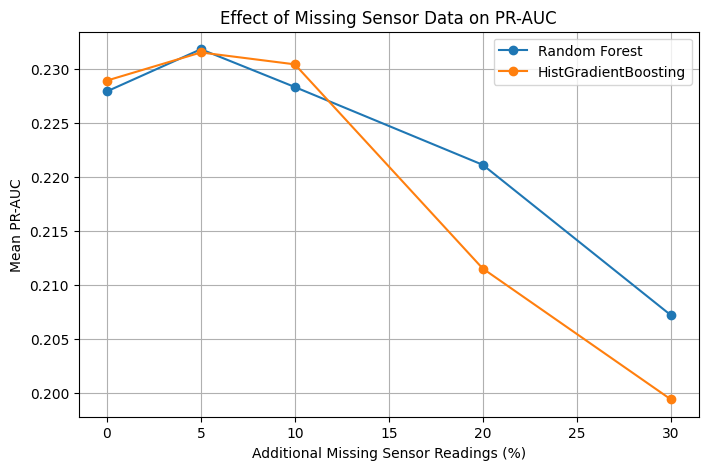

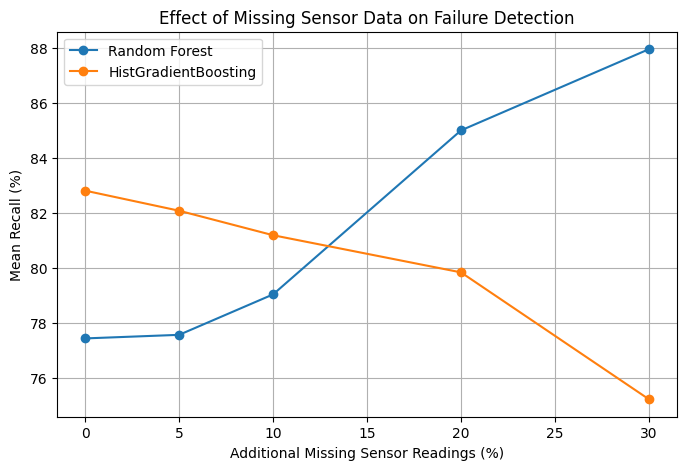

In [ ]:
import matplotlib.pyplot as plt

# Separate results for each model
rf_results = summary[
    summary["Model"] == "Random Forest"
]

hgb_results = summary[
    summary["Model"] == "HistGradientBoosting"
]

# Graph 1: PR-AUC
plt.figure(figsize=(8, 5))

plt.plot(
    rf_results["Missingness"] * 100,
    rf_results["PR_AUC_Mean"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    hgb_results["Missingness"] * 100,
    hgb_results["PR_AUC_Mean"],
    marker="o",
    label="HistGradientBoosting"
)

plt.xlabel("Additional Missing Sensor Readings (%)")
plt.ylabel("Mean PR-AUC")
plt.title("Effect of Missing Sensor Data on PR-AUC")
plt.legend()
plt.grid(True)
plt.show()

# Graph 2: Recall
plt.figure(figsize=(8, 5))

plt.plot(
    rf_results["Missingness"] * 100,
    rf_results["Recall_Mean"] * 100,
    marker="o",
    label="Random Forest"
)

plt.plot(
    hgb_results["Missingness"] * 100,
    hgb_results["Recall_Mean"] * 100,
    marker="o",
    label="HistGradientBoosting"
)

plt.xlabel("Additional Missing Sensor Readings (%)")
plt.ylabel("Mean Recall (%)")
plt.title("Effect of Missing Sensor Data on Failure Detection")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Extract and convert timestamps
timestamps = pd.to_datetime(labels.iloc[:, 1])

# Create a chronological dataset
temporal_data = X.copy()
temporal_data["Target"] = y.values
temporal_data["Timestamp"] = timestamps.values

# Sort observations by time
temporal_data = temporal_data.sort_values(
    "Timestamp"
).reset_index(drop=True)

# Display chronological information
print("TEMPORAL DATASET OVERVIEW")
print("-------------------------")

print("Total observations:", len(temporal_data))
print("Unique timestamps:", temporal_data["Timestamp"].nunique())

print(
    "First observation:",
    temporal_data["Timestamp"].min()
)

print(
    "Last observation:",
    temporal_data["Timestamp"].max()
)

print("\nMonthly failure rates:")

monthly_summary = (
    temporal_data
    .groupby(temporal_data["Timestamp"].dt.month)
    ["Target"]
    .agg(
        Total_Observations="count",
        Failures=lambda x: (x == 1).sum()
    )
)

monthly_summary["Failure_Rate"] = (
    monthly_summary["Failures"]
    / monthly_summary["Total_Observations"]
)

display(monthly_summary.round(4))

TEMPORAL DATASET OVERVIEW
-------------------------
Total observations: 1567
Unique timestamps: 1534
First observation: 2008-07-19 11:55:00
Last observation: 2008-10-17 06:07:00

Monthly failure rates:


/tmp/ipykernel_2324/858035162.py:2: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  timestamps = pd.to_datetime(labels.iloc[:, 1])


,Total_Observations,Failures,Failure_Rate
Timestamp,,,
7,63,14,0.2222
8,555,51,0.0919
9,590,17,0.0288
10,359,22,0.0613


In [ ]:
# Correctly parse the original date format
timestamps = pd.to_datetime(
    labels.iloc[:, 1],
    format="%d/%m/%Y %H:%M:%S"
)

# Rebuild the chronological dataset
temporal_data = X.copy()
temporal_data["Target"] = y.values
temporal_data["Timestamp"] = timestamps.values

temporal_data = temporal_data.sort_values(
    "Timestamp"
).reset_index(drop=True)

# Find unique timestamps in chronological order
unique_times = np.sort(
    temporal_data["Timestamp"].unique()
)

# Choose the 70% chronological cutoff
split_position = int(len(unique_times) * 0.70)
cutoff_time = unique_times[split_position]

# Split without separating identical timestamps
train_temporal = temporal_data[
    temporal_data["Timestamp"] < cutoff_time
].copy()

test_temporal = temporal_data[
    temporal_data["Timestamp"] >= cutoff_time
].copy()

# Display split information
print("CHRONOLOGICAL TRAIN-TEST SPLIT")
print("--------------------------------")

print("Cutoff date:", cutoff_time)

print("\nTraining observations:", len(train_temporal))
print("Training failures:", (train_temporal["Target"] == 1).sum())
print(
    "Training period:",
    train_temporal["Timestamp"].min(),
    "to",
    train_temporal["Timestamp"].max()
)

print("\nTesting observations:", len(test_temporal))
print("Testing failures:", (test_temporal["Target"] == 1).sum())
print(
    "Testing period:",
    test_temporal["Timestamp"].min(),
    "to",
    test_temporal["Timestamp"].max()
)

# Confirm that no timestamp is shared between the sets
overlap = set(train_temporal["Timestamp"]) & set(
    test_temporal["Timestamp"]
)

print("\nShared timestamps:", len(overlap))

CHRONOLOGICAL TRAIN-TEST SPLIT
--------------------------------
Cutoff date: 2008-09-26T02:26:00.000000000

Training observations: 1095
Training failures: 78
Training period: 2008-07-19 11:55:00 to 2008-09-26 01:21:00

Testing observations: 472
Testing failures: 26
Testing period: 2008-09-26 02:26:00 to 2008-10-17 06:07:00

Shared timestamps: 0


In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Separate sensor readings and failure labels
X_time = temporal_data[X.columns]
y_time = temporal_data["Target"]
time_values = temporal_data["Timestamp"]

# Use the existing chronological training and testing split
X_train_time = train_temporal[X.columns]
y_train_time = train_temporal["Target"]

X_test_time = test_temporal[X.columns]
y_test_time = test_temporal["Target"]

# Create an earlier training and later validation split
train_times = np.sort(
    train_temporal["Timestamp"].unique()
)

validation_cutoff = train_times[
    int(len(train_times) * 0.80)
]

subtrain_mask = (
    train_temporal["Timestamp"] < validation_cutoff
)

val_mask = ~subtrain_mask

X_subtrain = X_train_time.loc[subtrain_mask]
y_subtrain = y_train_time.loc[subtrain_mask]

X_val = X_train_time.loc[val_mask]
y_val = y_train_time.loc[val_mask]

print("TRAINING AND VALIDATION SETUP")
print("-----------------------------")
print("Subtraining observations:", len(X_subtrain))
print("Validation observations:", len(X_val))
print("Validation failures:", (y_val == 1).sum())

# Train, select threshold, and evaluate each model
temporal_results = []

for model_name in ["Random Forest", "HistGradientBoosting"]:

    model = clone(models[model_name])

    # Train using earlier observations
    model.fit(X_subtrain, y_subtrain)

    positive_index = list(model.classes_).index(1)

    # Predict on the later validation observations
    val_prob = model.predict_proba(X_val)[:, positive_index]

    # Choose the highest threshold achieving at least 80% recall
    thresholds = np.sort(np.unique(val_prob))

    valid_thresholds = [
        t for t in thresholds
        if recall_score(
            y_val,
            np.where(val_prob >= t, 1, -1),
            pos_label=1
        ) >= 0.80
    ]

    selected_threshold = (
        max(valid_thresholds)
        if valid_thresholds
        else thresholds.min()
    )

    # Retrain using the complete chronological training period
    final_model = clone(models[model_name])
    final_model.fit(X_train_time, y_train_time)

    # Evaluate on the untouched later testing period
    test_prob = final_model.predict_proba(
        X_test_time
    )[:, positive_index]

    test_predictions = np.where(
        test_prob >= selected_threshold,
        1,
        -1
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test_time,
        test_predictions,
        labels=[-1, 1]
    ).ravel()

    temporal_results.append({
        "Model": model_name,
        "Threshold": selected_threshold,
        "PR_AUC": average_precision_score(
            y_test_time == 1,
            test_prob
        ),
        "Precision": precision_score(
            y_test_time,
            test_predictions,
            pos_label=1,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_time,
            test_predictions,
            pos_label=1,
            zero_division=0
        ),
        "Inspection_Rate": np.mean(test_predictions == 1),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

    print(f"\n{model_name} completed.")
    print("Selected threshold:", round(selected_threshold, 4))

temporal_results_df = pd.DataFrame(temporal_results)

print("\nCHRONOLOGICAL TEST RESULTS")
display(temporal_results_df.round(4))

TRAINING AND VALIDATION SETUP
-----------------------------
Subtraining observations: 878
Validation observations: 217
Validation failures: 6

Random Forest completed.
Selected threshold: 0.0682

HistGradientBoosting completed.
Selected threshold: 0.0061

CHRONOLOGICAL TEST RESULTS


,Model,Threshold,PR_AUC,Precision,Recall,Inspection_Rate,TP,FP,TN,FN
0,Random Forest,0.0682,0.0641,0.0645,0.3077,0.2627,8,116,330,18
1,HistGradientBoosting,0.0061,0.0552,0.0488,0.3846,0.4343,10,195,251,16


### Chronological Model Evaluation

To investigate model performance on later manufacturing observations, a chronological training and testing strategy was implemented. The earlier 70% of unique timestamps was used for model development, while the remaining 30% was reserved for testing. A further chronological split within the training period was used for threshold selection.

The Random Forest model achieved a PR-AUC of 0.0641 and detected 8 out of 26 failed observations, whereas HistGradientBoosting achieved a PR-AUC of 0.0552 and detected 10 failures. Both models showed limited failure-detection capability on the later observations. Their low precision values also indicated a considerable number of false alarms.

Compared with the earlier grouped cross-validation results, this experiment revealed substantially weaker performance under chronological evaluation. This suggests that the learned patterns may not generalise reliably across time. However, the limited number of failures in the validation period and the use of a single chronological split restrict the strength of this conclusion. Further investigation is required to identify whether changes in sensor readings, process conditions or failure distributions contribute to the observed performance reduction.

In [ ]:
# Compare missing sensor readings between periods

train_sensor_data = train_temporal[X.columns]
test_sensor_data = test_temporal[X.columns]

train_missing = train_sensor_data.isna().mean().mean() * 100
test_missing = test_sensor_data.isna().mean().mean() * 100

train_failure_rate = (
    train_temporal["Target"] == 1
).mean() * 100

test_failure_rate = (
    test_temporal["Target"] == 1
).mean() * 100

comparison = pd.DataFrame({
    "Measurement": [
        "Observations",
        "Failure Rate (%)",
        "Missing Sensor Readings (%)"
    ],
    "Earlier Period": [
        len(train_temporal),
        round(train_failure_rate, 2),
        round(train_missing, 2)
    ],
    "Later Period": [
        len(test_temporal),
        round(test_failure_rate, 2),
        round(test_missing, 2)
    ]
})

print("EARLIER VS LATER MANUFACTURING DATA")
display(comparison)

EARLIER VS LATER MANUFACTURING DATA


,Measurement,Earlier Period,Later Period
0,Observations,1095.00,472.00
1,Failure Rate (%),7.12,5.51
2,Missing Sensor Readings (%),4.92,3.64


In [ ]:
# Compare sensor reading patterns across time

train_means = train_sensor_data.mean()
test_means = test_sensor_data.mean()

train_stds = train_sensor_data.std()

# Measure how much each sensor's average reading shifted
sensor_shift = (
    (test_means - train_means) / train_stds
).replace([np.inf, -np.inf], np.nan).dropna()

# Summarise the changes
print("SENSOR READING SHIFT ANALYSIS")
print("-----------------------------")

print("Sensors analysed:", len(sensor_shift))

print(
    "Sensors with shift above 1 standard deviation:",
    (sensor_shift.abs() > 1).sum()
)

print(
    "Sensors with shift above 2 standard deviations:",
    (sensor_shift.abs() > 2).sum()
)

print(
    "Average absolute shift:",
    round(sensor_shift.abs().mean(), 4)
)

print(
    "Largest absolute shift:",
    round(sensor_shift.abs().max(), 4)
)

# Display the 10 sensors with the largest shifts
print("\nTOP 10 SENSOR SHIFTS")

display(
    sensor_shift.abs()
    .sort_values(ascending=False)
    .head(10)
    .rename("Absolute_Shift")
    .to_frame()
)

SENSOR READING SHIFT ANALYSIS
-----------------------------
Sensors analysed: 468
Sensors with shift above 1 standard deviation: 13
Sensors with shift above 2 standard deviations: 8
Average absolute shift: 1.3437
Largest absolute shift: 264.5009

TOP 10 SENSOR SHIFTS


,Absolute_Shift
140,264.500927
275,210.128690
4,25.547544
516,3.966791
390,3.951687
252,3.798553
244,3.113769
382,3.091566
112,1.579534
517,1.517845


In [ ]:
# Investigate the two sensors with the largest shifts

sensors_to_check = [140, 275]

for sensor in sensors_to_check:

    earlier = train_sensor_data[sensor].dropna()
    later = test_sensor_data[sensor].dropna()

    print(f"\nSENSOR {sensor}")
    print("-" * 35)

    print("Earlier period:")
    print("Available readings:", len(earlier))
    print("Mean:", earlier.mean())
    print("Standard deviation:", earlier.std())
    print("Minimum:", earlier.min())
    print("Maximum:", earlier.max())

    print("\nLater period:")
    print("Available readings:", len(later))
    print("Mean:", later.mean())
    print("Standard deviation:", later.std())
    print("Minimum:", later.min())
    print("Maximum:", later.max())

    print("\nMean difference:", later.mean() - earlier.mean())


SENSOR 140
-----------------------------------
Earlier period:
Available readings: 1089
Mean: 0.3215963269054178
Standard deviation: 0.32591915003236527
Minimum: 0.0319
Maximum: 3.225

Later period:
Available readings: 464
Mean: 86.52751379310344
Standard deviation: 925.2860181566106
Minimum: 0.0522
Maximum: 9998.8944

Mean difference: 86.20591746619802

SENSOR 275
-----------------------------------
Earlier period:
Available readings: 1089
Mean: 0.10934325068870522
Standard deviation: 0.13672603777346923
Minimum: 0.0111
Maximum: 1.5361

Later period:
Available readings: 464
Mean: 28.83940646551724
Standard deviation: 308.3837714446579
Minimum: 0.0192
Maximum: 3332.5964

Mean difference: 28.730063214828533


In [ ]:
for sensor in [140, 275]:

    earlier = train_sensor_data[sensor].dropna()
    later = test_sensor_data[sensor].dropna()

    print(f"\nSENSOR {sensor}")
    print("=" * 45)

    print("\nEarlier period distribution:")
    print(earlier.quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]))

    print("\nLater period distribution:")
    print(later.quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]))

    print("\nLater readings above 10:")
    print((later > 10).sum())

    print("Later readings above 100:")
    print((later > 100).sum())

    print("Later readings above 1000:")
    print((later > 1000).sum())


SENSOR 140

Earlier period distribution:
0.00    0.03190
0.25    0.13180
0.50    0.23610
0.75    0.42870
0.90    0.57620
0.95    0.65394
0.99    1.57730
1.00    3.22500
Name: 140, dtype: float64

Later period distribution:
0.00       0.052200
0.25       0.129350
0.50       0.235200
0.75       0.464825
0.90       0.699600
0.95       1.157315
0.99       1.346912
1.00    9998.894400
Name: 140, dtype: float64

Later readings above 10:
4
Later readings above 100:
4
Later readings above 1000:
4

SENSOR 275

Earlier period distribution:
0.00    0.01110
0.25    0.04610
0.50    0.07910
0.75    0.14060
0.90    0.19602
0.95    0.23390
0.99    0.46110
1.00    1.53610
Name: 275, dtype: float64

Later period distribution:
0.00       0.019200
0.25       0.044100
0.50       0.070850
0.75       0.161600
0.90       0.223100
0.95       0.405550
0.99       0.511121
1.00    3332.596400
Name: 275, dtype: float64

Later readings above 10:
4
Later readings above 100:
4
Later readings above 1000:
4


In [ ]:
# Compare sensor medians using the earlier period's IQR as the scale.
# IQR = interquartile range (75th percentile - 25th percentile).

train_median = train_sensor_data.median()
test_median = test_sensor_data.median()

train_iqr = (
    train_sensor_data.quantile(0.75)
    - train_sensor_data.quantile(0.25)
)

robust_shift = (
    (test_median - train_median) / train_iqr
).replace([np.inf, -np.inf], np.nan).dropna()

print("Sensors analysed:", len(robust_shift))
print("Sensors with absolute median shift > 1 IQR:",
      (robust_shift.abs() > 1).sum())
print("Sensors with absolute median shift > 2 IQR:",
      (robust_shift.abs() > 2).sum())
print("Average absolute median shift:", robust_shift.abs().mean())

print("\nTop 10 sensors by absolute median shift:")
print(robust_shift.abs().sort_values(ascending=False).head(10))

Sensors analysed: 460
Sensors with absolute median shift > 1 IQR: 6
Sensors with absolute median shift > 2 IQR: 1
Average absolute median shift: 0.2352214384227414

Top 10 sensors by absolute median shift:
116    2.400000
109    1.413793
383    1.256416
245    1.179727
517    1.173310
318    1.057471
95     1.000000
34     0.953368
36     0.953368
28     0.920341
dtype: float64


### Sensor Distribution Shift Analysis

To investigate whether changes in sensor readings could explain the reduced performance during chronological testing, sensor distributions in the earlier and later periods were compared. An initial mean-based analysis identified unusually large shifts in some sensors. Further inspection showed that Sensors 140 and 275 contained only four extremely high readings each in the later period, which strongly influenced their means and standard deviations.

A more robust comparison using sensor medians and interquartile ranges was then performed across 460 sensors. Only six sensors showed a median shift greater than one interquartile range, and only one exceeded two interquartile ranges. The average absolute shift was 0.235 interquartile ranges.

These results suggest that large distribution changes were not widespread across the analysed sensors. Therefore, the poor chronological test performance cannot be attributed to general sensor drift based on this analysis alone. Further investigation would be required to identify the cause of the reduced performance.

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# Use the first outer grouped-CV split
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    outer_cv.split(X, y, groups=timestamps)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Build the Random Forest pipeline
rf_importance_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("model", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_importance_model.fit(X_train, y_train)

# Check its baseline performance
baseline_probabilities = rf_importance_model.predict_proba(X_test)[:, 1]

baseline_ap = average_precision_score(
    (y_test == 1).astype(int),
    baseline_probabilities
)

print("Baseline test PR-AUC:", round(baseline_ap, 4))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Baseline test PR-AUC: 0.2436
Training observations: 1253
Testing observations: 314


In [ ]:
importance_result = permutation_importance(
    rf_importance_model,
    X_test,
    (y_test == 1).astype(int),
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Get the importance scores
importance_scores = pd.DataFrame({
    "Sensor": X.columns,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
})

# Sort from most important to least important
importance_scores = importance_scores.sort_values(
    by="Importance_Mean",
    ascending=False
)

print("Top 15 most important sensors:")
display(importance_scores.head(15))

Top 15 most important sensors:


,Sensor,Importance_Mean,Importance_Std
65,65,0.004089,0.003739
280,280,0.003587,0.002875
485,485,0.003224,0.001461
152,152,0.002740,0.003355
67,67,0.002004,0.000954
336,336,0.001913,0.004112
429,429,0.001549,0.003270
351,351,0.001401,0.007598
338,338,0.001264,0.001482
211,211,0.001236,0.001387


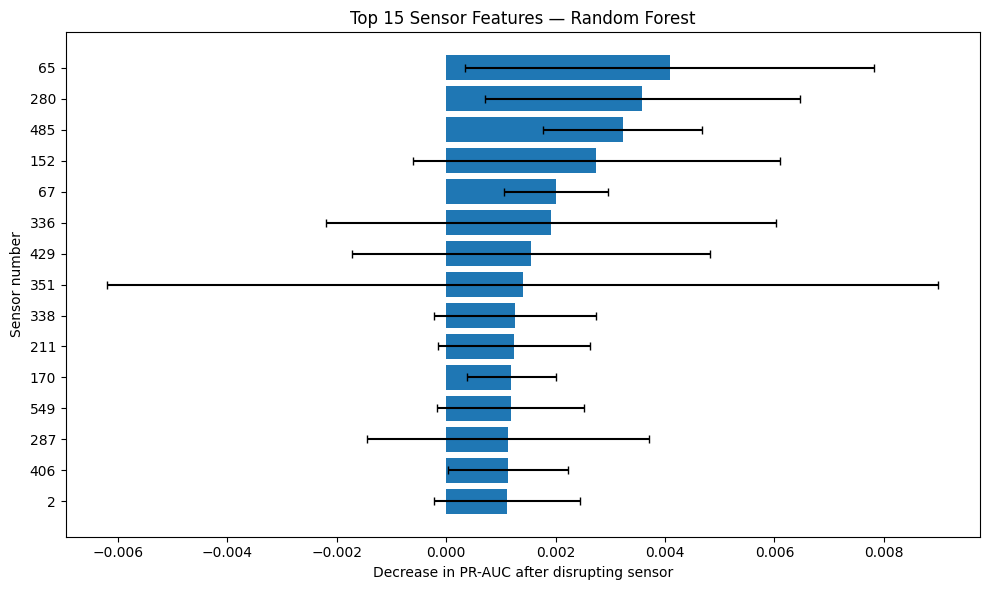

In [ ]:
import matplotlib.pyplot as plt

top_sensors = importance_scores.head(15).sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_sensors["Sensor"].astype(str),
    top_sensors["Importance_Mean"],
    xerr=top_sensors["Importance_Std"],
    capsize=3
)

plt.xlabel("Decrease in PR-AUC after disrupting sensor")
plt.ylabel("Sensor number")
plt.title("Top 15 Sensor Features — Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
# Print a readable interpretation of the importance graph

print("SENSOR IMPORTANCE GRAPH — NUMERICAL SUMMARY")
print("=" * 55)

for rank, (_, row) in enumerate(
    importance_scores.head(15).iterrows(), start=1
):
    print(
        f"Rank {rank}: Sensor {int(row['Sensor'])} | "
        f"Importance = {row['Importance_Mean']:.6f} | "
        f"Variation = {row['Importance_Std']:.6f}"
    )

print("\nGRAPH INTERPRETATION")
print("=" * 55)

top = importance_scores.iloc[0]

print(
    f"Most important sensor: {int(top['Sensor'])}"
)
print(
    f"Largest average PR-AUC decrease: "
    f"{top['Importance_Mean']:.6f}"
)

positive = (importance_scores["Importance_Mean"] > 0).sum()
negative = (importance_scores["Importance_Mean"] < 0).sum()

print("Sensors with positive importance:", positive)
print("Sensors with negative importance:", negative)

print(
    "\nImportance scores are measured as the reduction in "
    "PR-AUC after randomly shuffling a sensor's values."
)

SENSOR IMPORTANCE GRAPH — NUMERICAL SUMMARY
Rank 1: Sensor 65 | Importance = 0.004089 | Variation = 0.003739
Rank 2: Sensor 280 | Importance = 0.003587 | Variation = 0.002875
Rank 3: Sensor 485 | Importance = 0.003224 | Variation = 0.001461
Rank 4: Sensor 152 | Importance = 0.002740 | Variation = 0.003355
Rank 5: Sensor 67 | Importance = 0.002004 | Variation = 0.000954
Rank 6: Sensor 336 | Importance = 0.001913 | Variation = 0.004112
Rank 7: Sensor 429 | Importance = 0.001549 | Variation = 0.003270
Rank 8: Sensor 351 | Importance = 0.001401 | Variation = 0.007598
Rank 9: Sensor 338 | Importance = 0.001264 | Variation = 0.001482
Rank 10: Sensor 211 | Importance = 0.001236 | Variation = 0.001387
Rank 11: Sensor 170 | Importance = 0.001193 | Variation = 0.000806
Rank 12: Sensor 549 | Importance = 0.001177 | Variation = 0.001340
Rank 13: Sensor 287 | Importance = 0.001130 | Variation = 0.002580
Rank 14: Sensor 406 | Importance = 0.001127 | Variation = 0.001099
Rank 15: Sensor 2 | Importanc

### Sensor Feature Importance Analysis

Permutation importance was used to investigate how individual sensor features influenced the Random Forest model's predictions. The experiment was performed on one grouped test fold using ten repetitions for each feature.

Sensor 65 showed the highest average importance, with a PR-AUC decrease of 0.004089 after its readings were shuffled. Sensors 280 and 485 followed with importance scores of 0.003587 and 0.003224, respectively.

However, the importance values were generally small, and several features showed considerable variation across repetitions. Of the 590 sensor features, 60 had positive average importance scores, while 407 had negative scores; the remaining features had zero importance or were not represented by a usable score.

These findings suggest that no single sensor feature dominated the model's predictions in this test fold. The results are exploratory because the analysis used only one test fold, and the physical meanings of the anonymised sensor columns are unavailable. Further validation across multiple folds would be required before drawing stronger conclusions.